<div style="text-align:center; background-color:#17365D; padding:20px; border-radius:10px;">

<h1 style="color:white;">SOCIAL MEDIA ENGAGEMENT ANALYTICS</h1>

</div>

<h2 style="color:#2563EB; text-align:left;">
1. Introduction
</h2>

<p style="text-align:left;">
Social media platforms generate large amounts of data such as
likes, comments, shares, impressions and watch time.
</p>

<p style="text-align:left;">
In this project, we use Python to analyze social media engagement
data, identify patterns and generate meaningful insights.
</p>

<div style=padding:15px; border-radius:10px; text-align:left;">
<h2 style="color:green;">TASK 1: DATA IMPORT & SETUP</h2>
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

<h3 style="color:#16A34A; text-align:left;">
1.2 Loading the Dataset
</h3>


In [7]:
df=pd.read_csv("social_media_engagement_5000.csv")
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [5]:
df.shape

(5000, 19)

In [6]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

<h3 style="color:#16A34A; text-align:left;">
1.2 Checking Data Types of Columns
</h3>

In [8]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [12]:
df["posted_at"]=pd.to_datetime(df["posted_at"],dayfirst=True)

In [13]:
df.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

<h3 style="color:#16A34A; text-align:left;">
1.3 Basic NumPy Array Operations
</h3>

In [15]:
likes_arr = np.array(df['likes'])
comments_arr = np.array(df['comments'])
shares_arr = np.array(df['shares'])

# Calculate basic statistics
print("Total Likes:", np.sum(likes_arr))
print("Average Likes:", np.mean(likes_arr))
print("Maximum Likes:", np.max(likes_arr))
print("Minimum Likes:", np.min(likes_arr))

Total Likes: nan
Average Likes: nan
Maximum Likes: nan
Minimum Likes: nan


In [16]:
df['likes'].isnull().sum()

np.int64(150)

In [17]:
print("Total Likes:", np.nansum(likes_arr))
print("Average Likes:", np.nanmean(likes_arr))
print("Maximum Likes:", np.nanmax(likes_arr))
print("Minimum Likes:", np.nanmin(likes_arr))

Total Likes: 49019162.0
Average Likes: 10107.043711340206
Maximum Likes: 19998.0
Minimum Likes: 10.0


<div style=padding:15px; border-radius:10px; text-align:left;">
<h2 style="color:Red;">TASK 2: DATA CLEANING</h2>
</div>

<h3 style="color:#1976D2;">2.1.1 Detecting Missing Values</h3>


In [20]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

<h3 style="color:#1976D2;">2.1.2 Handling Missing Values</h3>

In [21]:
for col in ['age', 'likes', 'comments', 'shares']:
    df[col] = df[col].fillna(df[col].median())

for col in ['gender', 'sentiment']:
    df[col] = df[col].fillna(df[col].mode()[0])

In [22]:
df.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

<h3 style="color:#1976D2;">2.2 Checking Duplicate Records</h3>

In [26]:
# Count duplicate rows
print("Number of duplicate rows:",df.duplicated().sum())

Number of duplicate rows: 0


<h3 style="color:#0D6EFD;">2.3 Checking Data Types and Formatting</h3>

In [27]:
df.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

<h4 style="color:#198754;">2.3.1 Converting Numerical Columns</h4>

In [32]:
df[['likes', 'comments', 'shares','age']] = df[['likes', 'comments', 'shares','age']].astype('int64')

In [33]:
df.dtypes

user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

<h4 style="color:#0D6EFD;">2.3.2 Standardizing Categorical Values</h4>

In [35]:
df['gender'].value_counts()

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

In [36]:
df['gender'] = df['gender'].str.strip().str.title()

In [37]:
df['gender'].value_counts()

gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64

<h4 style="color:#DC3545;">2.3.3 Checking Unrealistic Values</h4>

In [42]:
print("Negative ages:", (df['age'] < 0).sum())
print("Negative likes:", (df['likes'] < 0).sum())
print("Negative comments:", (df['comments'] < 0).sum())
print("Negative shares:", (df['shares'] < 0).sum())

Negative ages: 0
Negative likes: 0
Negative comments: 0
Negative shares: 0


<h3 style="color:#198754;">2.4 Feature Cleaning</h3>

<h4 style="color:#DC3545;">2.4.1 Extract hashtag count</h4>

In [45]:
df['hashtags'].head()

0    #foodie #travel #love
1                 #fitness
2                  #foodie
3      #music #foodie #fun
4                  #travel
Name: hashtags, dtype: str

In [46]:
df['hashtag_count'] = df['hashtags'].str.split().str.len()

In [47]:
df[['hashtags', 'hashtag_count']].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


<h4 style="color:#DC3545;">2.4.2 Clean sentiment labels</h4>

In [52]:
df['sentiment'].value_counts()

sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64

In [54]:
df['sentiment'] = df['sentiment'].str.strip().str.title()

In [63]:
print(df['sentiment'].unique())

<ArrowStringArray>
['Negative', 'Positive', 'Neutral']
Length: 3, dtype: str


<div style=padding:15px; border-radius:10px; text-align:left;">
<h2 style="color:Blue;">TASK 3: DATA EXPLORATION USING PANDAS</h2>
</div>

In [50]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,Negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,Negative,#fitness,0.201493,1
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,Positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,Negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,Negative,#travel,2.777372,1


In [51]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,Positive,#travel #fun,0.466761,2
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,Negative,#foodie #reels,0.621155,2
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,Positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,Positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,text,travel,14830,503,1798,3743,14234,2023-03-04,585760,False,desktop,Neutral,#foodie #lifestyle #fashion,1.203527,3


In [56]:
df.shape

(5000, 20)

In [57]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   str           
 3   country           5000 non-null   str           
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   str           
 6   post_category     5000 non-null   str           
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[us]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 non-null   b

In [59]:
df.dtypes

user_id                      int64
age                          int64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

In [60]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.982400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293022,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


<h3 style="color:#0D6EFD;">3.1 Analyze categorical distributions</h3>

In [65]:
df['post_type'].value_counts()

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

In [66]:
print("Post types:")
print(df['post_type'].unique())

print("\nNumber of unique post types:")
print(df['post_type'].nunique())

Post types:
<ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str

Number of unique post types:
4


<h3 style="color:#0D6EFD;">3.2 Correlation Matrix</h3>

In [68]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()
correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036323,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036323,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093521,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093521,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


<h3 style="color:#198754;">3.3 Grouping and Summarizing Data</h3>

In [69]:
avg_likes = df.groupby('post_type')['likes'].mean()
avg_likes

post_type
image    10104.852446
reel     10037.784879
text     10100.132530
video    10188.586122
Name: likes, dtype: float64

In [71]:
Average_Impressions_by_Country=df.groupby('country')['impression_count'].mean()
Average_Impressions_by_Country

country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64

<div style=padding:15px; border-radius:10px; text-align:left;">
<h2 style="color:orange;">TASK 4: DATA WRANGLING</h2>
</div>

<h3 style="color:#0D6EFD;">4.1 Creating New Fields</h3>

In [72]:
df['engagement_score'] = (df['likes'] + df['comments'] + df['shares'])
df[['likes', 'comments', 'shares', 'engagement_score']].head()

,likes,comments,shares,engagement_score
0,7011,354,1157,8522
1,11750,2606,1807,16163
2,4862,344,955,6161
3,5350,1083,1049,7482
4,12682,2735,1300,16717


In [73]:
df['log_likes'] = np.log1p(df['likes'])
df[['likes', 'log_likes']].head()

,likes,log_likes
0,7011,8.855378
1,11750,9.371694
2,4862,8.489411
3,5350,8.585039
4,12682,9.448018


In [74]:
df[['hashtags', 'hashtag_count']].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


<h3 style="color:#198754;">4.2 Groupby Summaries</h3>

In [79]:
# Average engagement metrics by post type
print("Average Engagement by Post Type:")
display(df.groupby('post_type')[['likes', 'comments', 'shares', 'engagement_score']].mean())

Average Engagement by Post Type:


,likes,comments,shares,engagement_score
post_type,,,,
image,10104.852446,1525.235766,1019.289495,12649.377706
reel,10037.784879,1504.187062,982.042089,12524.014030
text,10100.132530,1499.106024,1013.989558,12613.228112
video,10188.586122,1479.160000,996.834286,12664.580408


In [77]:
# Average engagement metrics by country
print("Average Engagement by Country:")
display(df.groupby('country')[['likes', 'comments', 'shares', 'engagement_score']].mean())

Average Engagement by Country:


,likes,comments,shares,engagement_score
country,,,,
Australia,10294.107505,1485.803245,1029.693712,12809.604462
Brazil,9886.678571,1490.434524,1008.859127,12385.972222
Canada,10063.054581,1546.582846,996.245614,12605.883041
France,10372.862903,1478.695565,1051.812500,12903.370968
Germany,10130.434694,1531.826531,973.379592,12635.640816
India,9962.444860,1494.917757,1035.315888,12492.678505
Japan,10088.851695,1530.434322,959.351695,12578.637712
UAE,10227.473161,1541.214712,989.075547,12757.763419
UK,9935.636917,1463.042596,985.681542,12384.361055


In [78]:
# Average engagement metrics by sentiment
print("Average Engagement by Sentiment:")
display(df.groupby('sentiment')[['likes', 'comments', 'shares', 'engagement_score']].mean())

Average Engagement by Sentiment:


,likes,comments,shares,engagement_score
sentiment,,,,
Negative,10208.081250,1516.094792,1007.307292,12731.483333
Neutral,9923.180092,1528.404060,996.565160,12448.149312
Positive,10180.046956,1480.650617,1005.086749,12665.784322


<div style=padding:15px; border-radius:10px; text-align:left;">
<h2 style="color:violet;">TASK 5: STATISTICAL ANALYSIS</h2>
</div>

In [86]:
columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

for col in columns:
    print(f"\nStatistics for {col}")
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])


Statistics for likes
Mean: 10106.9824
Median: 10105.0
Mode: 10105

Statistics for comments
Mean: 1502.0398
Median: 1497.0
Mode: 1497

Statistics for shares
Mean: 1002.9106
Median: 1012.0
Mode: 1012

Statistics for watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916

Statistics for engagement_rate
Mean: 0.9643560291583999
Median: 0.2538959065
Mode: 0.006362909

Statistics for follower_count
Mean: 393698.2248
Median: 388982.0
Mode: 497502


In [87]:
for col in columns:
    print(f"\nStatistics for {col}")
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())


Statistics for likes
Standard Deviation: 5702.293021761636
Variance: 32516145.706031445

Statistics for comments
Standard Deviation: 856.3933120458984
Variance: 733409.5049169434

Statistics for shares
Standard Deviation: 570.8551999758852
Variance: 325875.65933950787

Statistics for watch_time_sec
Standard Deviation: 2308.0964590420845
Variance: 5327309.264242608

Statistics for engagement_rate
Standard Deviation: 5.31802922266154
Variance: 28.281434813082104

Statistics for follower_count
Standard Deviation: 230927.88453461003
Variance: 53327687855.63019


In [88]:
for col in columns:
    print(f"\nPercentiles for {col}")
    print("25th Percentile:", df[col].quantile(0.25))
    print("50th Percentile:", df[col].quantile(0.50))
    print("75th Percentile:", df[col].quantile(0.75))


Percentiles for likes
25th Percentile: 5235.0
50th Percentile: 10105.0
75th Percentile: 14959.0

Percentiles for comments
25th Percentile: 792.0
50th Percentile: 1497.0
75th Percentile: 2235.25

Percentiles for shares
25th Percentile: 511.0
50th Percentile: 1012.0
75th Percentile: 1483.0

Percentiles for watch_time_sec
25th Percentile: 2017.75
50th Percentile: 4034.5
75th Percentile: 6020.25

Percentiles for engagement_rate
25th Percentile: 0.14578108750000002
50th Percentile: 0.2538959065
75th Percentile: 0.504793702

Percentiles for follower_count
25th Percentile: 194480.0
50th Percentile: 388982.0
75th Percentile: 589744.25


In [89]:
for col in columns:
    print(f"\nStatistics for {col}")
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


Statistics for likes
Skewness: -0.0068857217962518535
Kurtosis: -1.1499924394060148

Statistics for comments
Skewness: 0.0038017289479831415
Kurtosis: -1.1443748352968992

Statistics for shares
Skewness: -0.014653583910311461
Kurtosis: -1.1468565626589917

Statistics for watch_time_sec
Skewness: -0.018196273193231846
Kurtosis: -1.195651797070188

Statistics for engagement_rate
Skewness: 18.781270878869154
Kurtosis: 482.9917386319569

Statistics for follower_count
Skewness: 0.04111777394961326
Kurtosis: -1.1894740478821386


<div style=padding:15px; border-radius:10px; text-align:left;">
<h2 style="color:magenta;">TASK 6: DATA VISUALIZATION</h2>
</div>

<h3 style="color:blue;">6.1. Scatter Plot – Likes vs Impressions</h3>

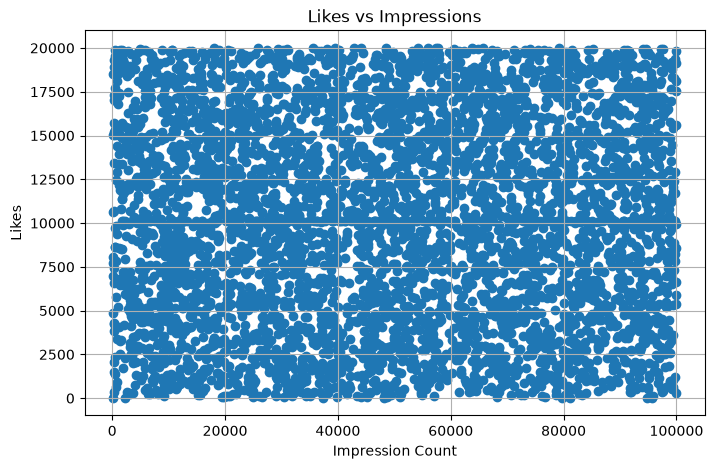

In [93]:
plt.figure(figsize=(8, 5))
plt.scatter(df['impression_count'], df['likes'])
plt.title('Likes vs Impressions')
plt.xlabel('Impression Count')
plt.ylabel('Likes')
plt.grid(True)
plt.show()

<h3 style="color:blue;">6.2. Line Plot – Daily Engagement Trend</h3>

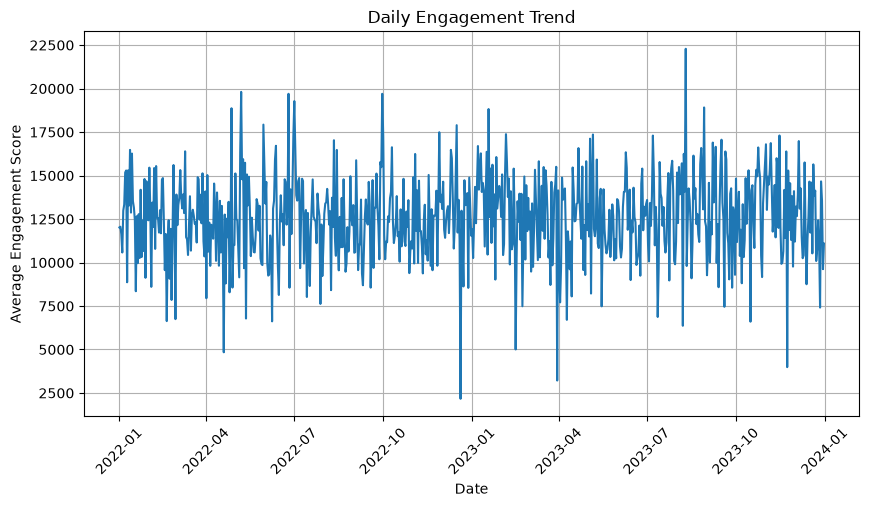

In [94]:
daily_engagement = df.groupby(df['posted_at'].dt.date)['engagement_score'].mean()
plt.figure(figsize=(10, 5))
plt.plot(daily_engagement.index, daily_engagement.values)
plt.title('Daily Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Average Engagement Score')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

<h3 style="color:blue;">6.3. Histogram – Age Distribution</h3>

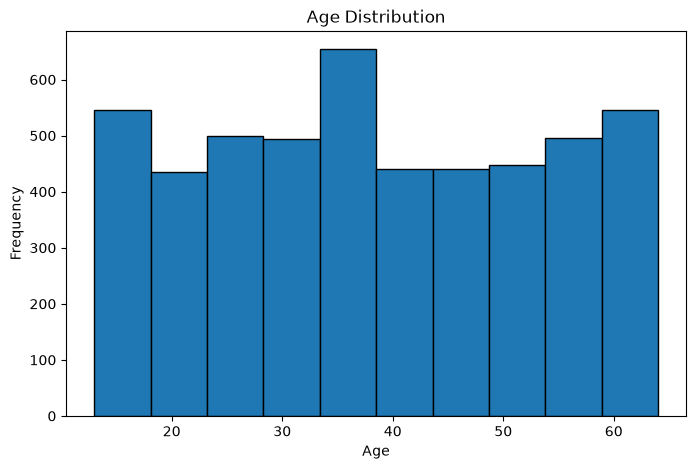

In [96]:
plt.figure(figsize=(8, 5))
plt.hist(df['age'], bins=10, edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

<h3 style="color:blue;">6.4. Box Plot – Engagement Rate Distribution</h3>

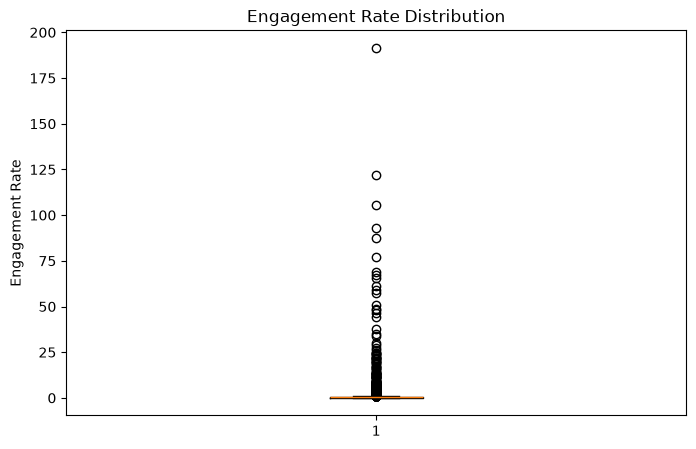

In [97]:
plt.figure(figsize=(8, 5))
plt.boxplot(df['engagement_rate'])
plt.title('Engagement Rate Distribution')
plt.ylabel('Engagement Rate')
plt.show()

<h3 style="color:blue;">6.5 Violin Plot – Followers vs Sentiment</h3>

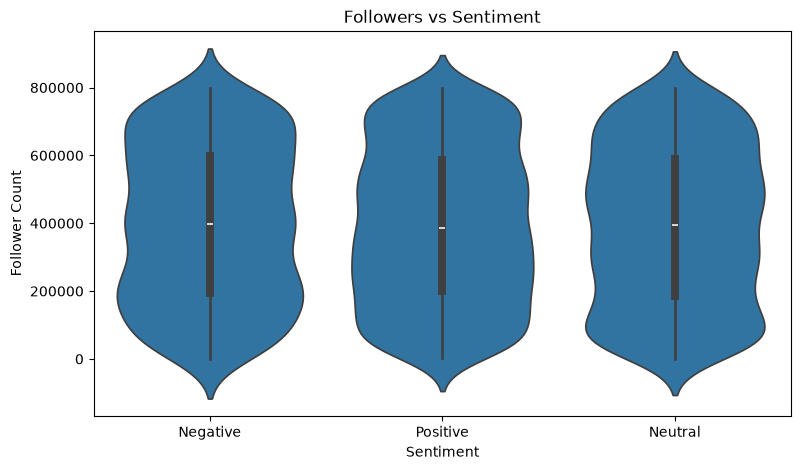

In [98]:
plt.figure(figsize=(9, 5))
sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)
plt.title('Followers vs Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.show()

<h3 style="color:blue;">6.6 Pair Plot – Numeric Features</h3>

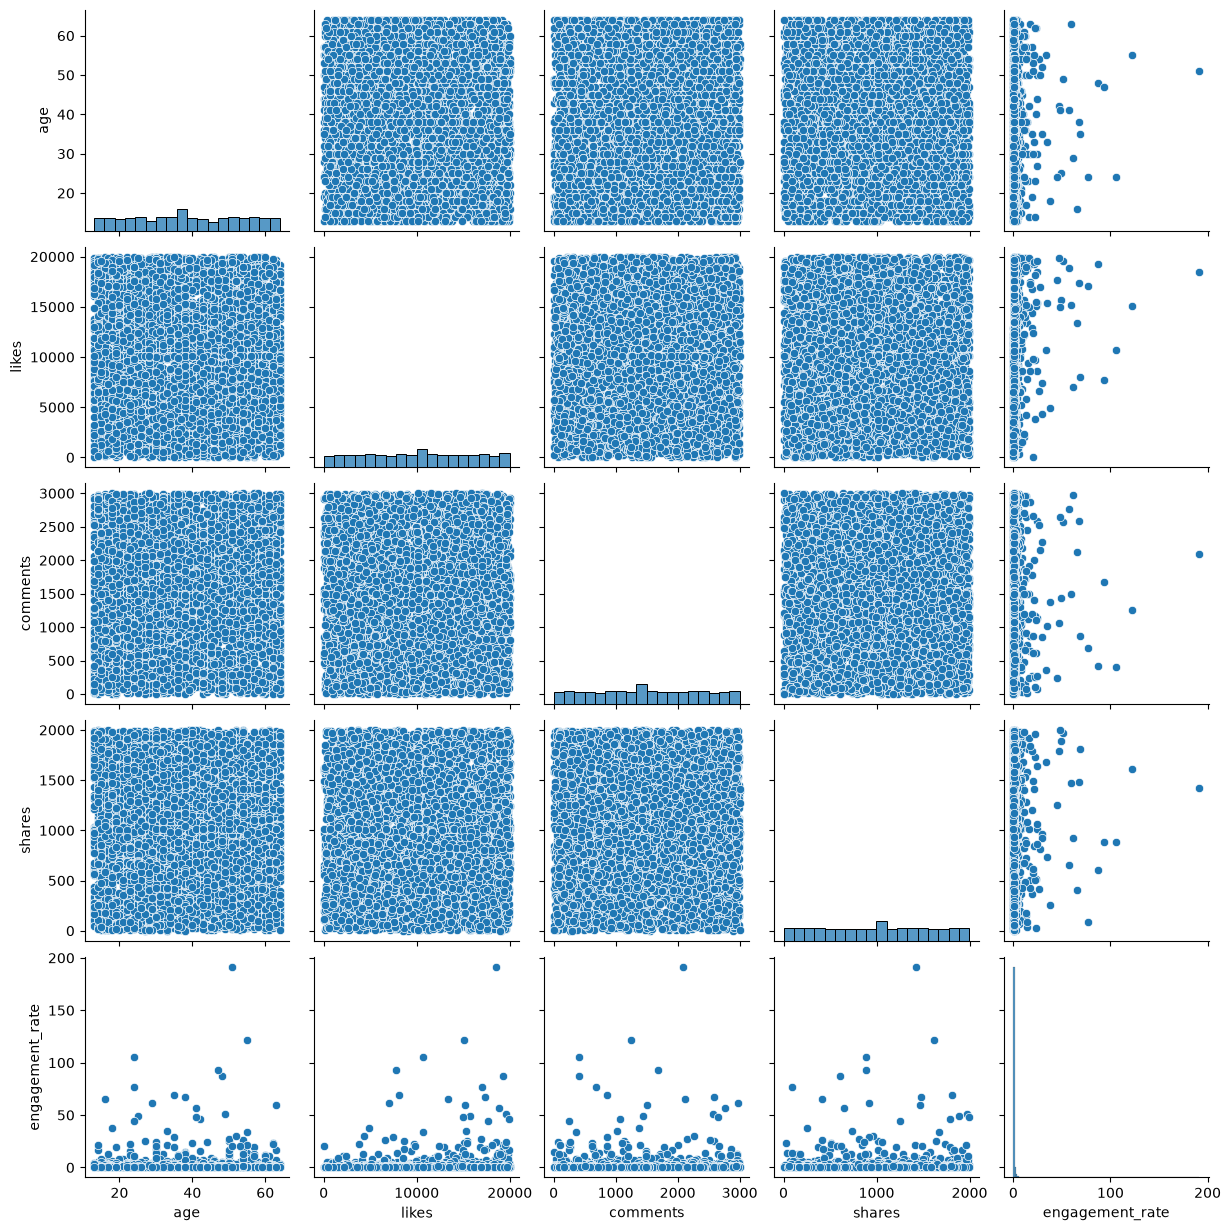

In [99]:
numeric_features = df[['age', 'likes', 'comments', 'shares', 'engagement_rate']]
sns.pairplot(numeric_features)
plt.show()

<h3 style="color:blue;">6.7 Heatmap – Correlation Matrix</h3>

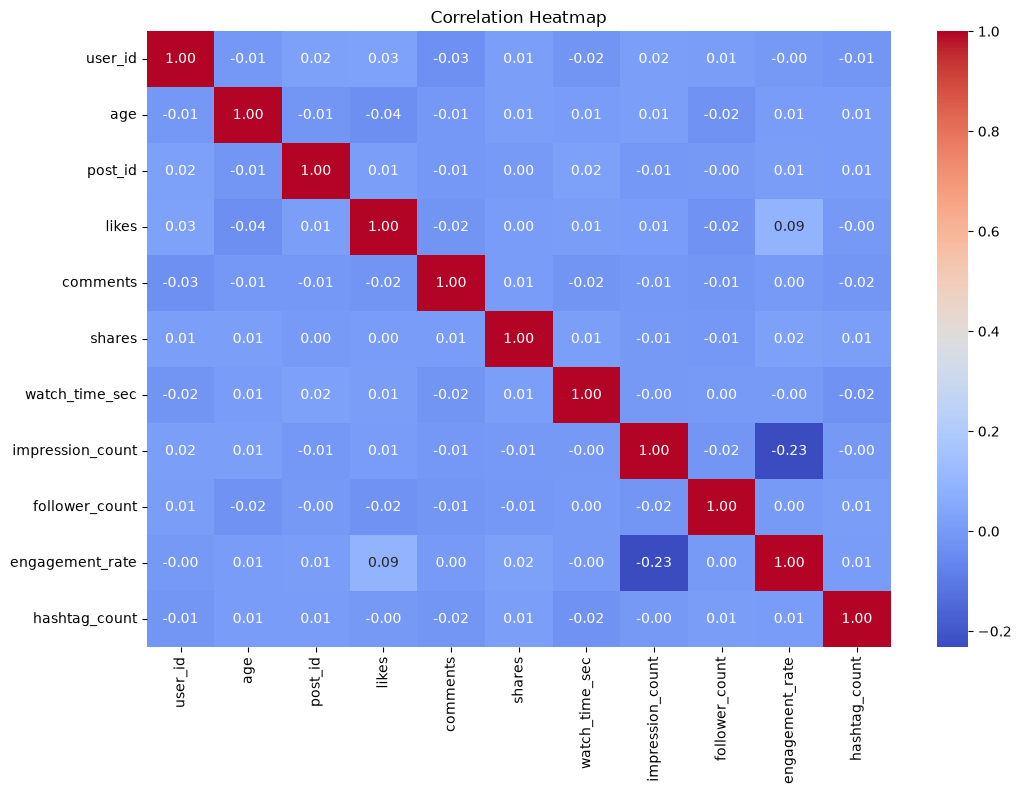

In [100]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap')
plt.show()

<h3 style="color:blue;">6.8 Swarm Plot – Engagement vs Device</h3>

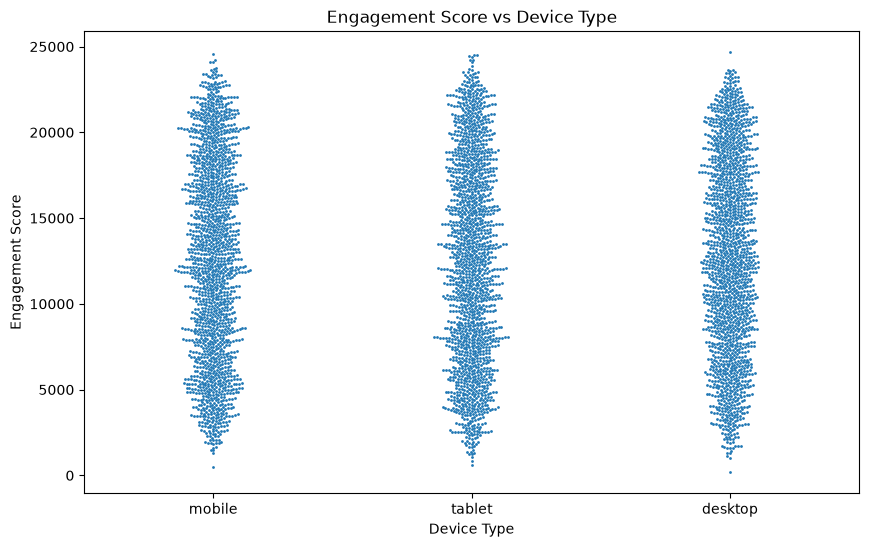

In [102]:
plt.figure(figsize=(10, 6))
sns.swarmplot(
    data=df,
    x='device_type',
    y='engagement_score',
    size=2
)
plt.title('Engagement Score vs Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Score')
plt.show()

<h3 style="color:blue;">6.9 Plotly Interactive Visualizations</h3>

<h4 style="color:blue;">6.9.1 Interactive Line Chart – Daily Engagement Trend</h4>

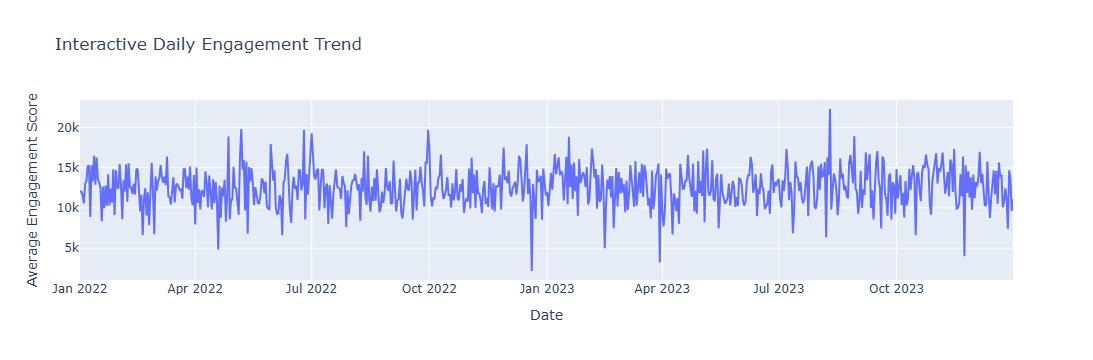

In [104]:
fig = px.line(
    x=daily_engagement.index,
    y=daily_engagement.values,
    title='Interactive Daily Engagement Trend',
    labels={
        'x': 'Date',
        'y': 'Average Engagement Score'
    }
)
fig.show()

<h4 style="color:blue;">6.9.2 Interactive Bar Chart – Average Likes by Category</h4>

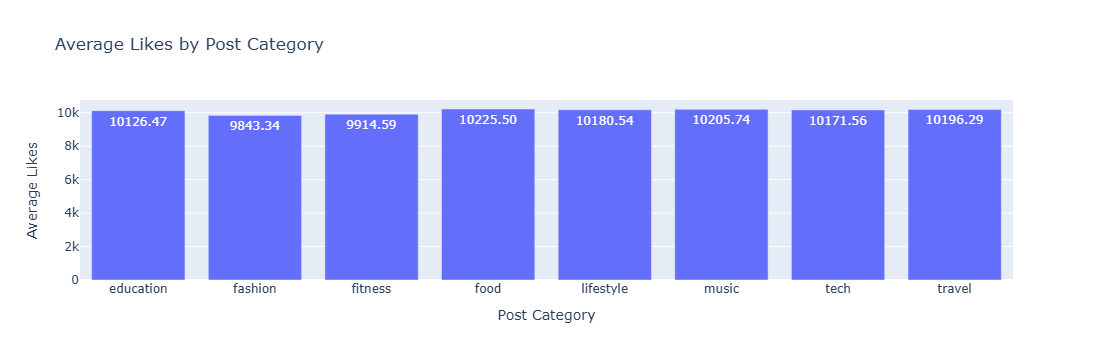

In [106]:
category_likes = df.groupby('post_category')['likes'].mean().reset_index()
fig = px.bar(
    category_likes,
    x='post_category',
    y='likes',
    title='Average Likes by Post Category',
    labels={
        'post_category': 'Post Category',
        'likes': 'Average Likes'
    },
    text_auto='.2f'
)
fig.show()

<h4 style="color:blue;">6.9.3 Interactive Bubble Chart – Likes, Comments and Shares</h4>

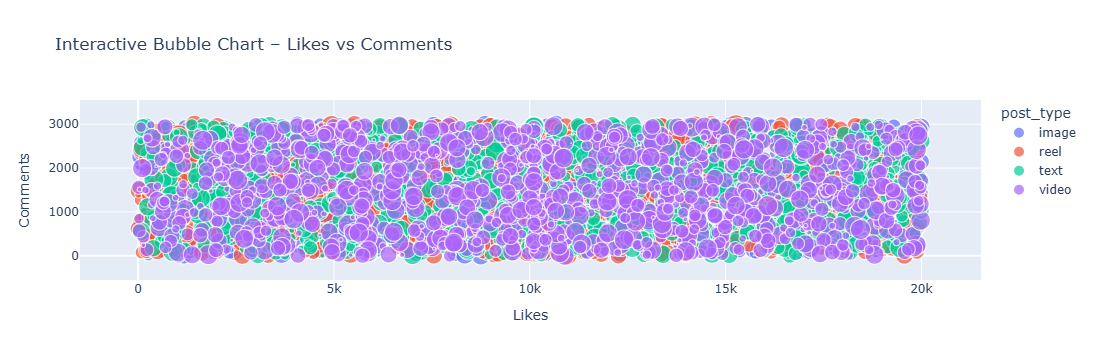

In [110]:
fig = px.scatter(
    df,
    x='likes',
    y='comments',
    size='shares',
    color='post_type',
    hover_data=['country', 'sentiment'],
    title='Interactive Bubble Chart – Likes vs Comments',
    labels={
        'likes': 'Likes',
        'comments': 'Comments',
        'shares': 'Shares'
    }
)
fig.show()

<h4 style="color:blue;">6.9.4. Interactive Scatter Chart – Followers vs Engagement</h4>

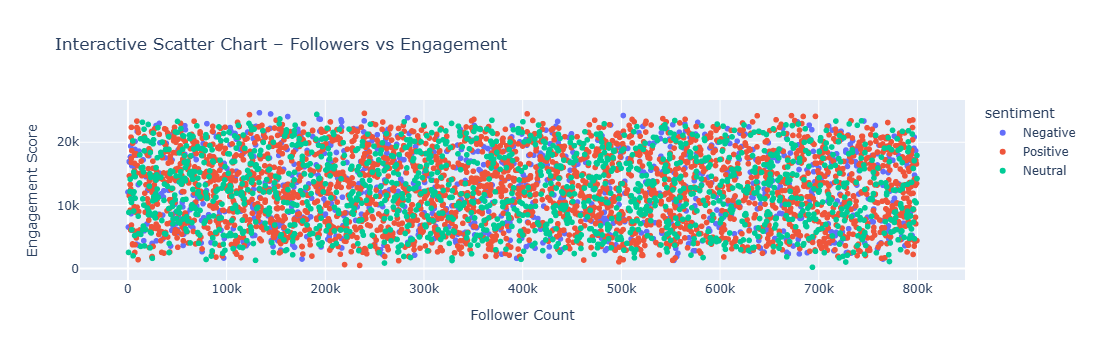

In [111]:
fig = px.scatter(
    df,
    x='follower_count',
    y='engagement_score',
    color='sentiment',
    hover_data=['post_type', 'country'],
    title='Interactive Scatter Chart – Followers vs Engagement',
    labels={
        'follower_count': 'Follower Count',
        'engagement_score': 'Engagement Score'
    }
)
fig.show()

<div style=padding:15px; border-radius:10px; text-align:left;">
<h2 style="color:GREEN;">TASK 7: FINAL INSIGHTS</h2>
</div>

<h4 style="color:green;">1. Which Post Types Have the Highest Engagement?</h4>

<p>Analyse the average engagement score for each post type to identify which type performs best.</p>

In [112]:
post_type_engagement = df.groupby('post_type')['engagement_score'].mean().sort_values(ascending=False)
display(post_type_engagement)

post_type
video    12664.580408
image    12649.377706
text     12613.228112
reel     12524.014030
Name: engagement_score, dtype: float64

<h4 style="color:green;">2. Best-Performing Content Category</h4>

<p>Analyse the average engagement score across different content categories to identify the best-performing category.</p>

In [113]:
category_engagement = df.groupby('post_category')['engagement_score'].mean().sort_values(ascending=False)
display(category_engagement)

post_category
music        12788.537008
food         12739.180438
tech         12686.479699
travel       12650.545000
lifestyle    12639.517298
education    12578.255151
fitness      12457.780741
fashion      12356.405724
Name: engagement_score, dtype: float64

<h4 style="color:green;">3. Countries with the Highest Average Engagement Rate</h4>

<p>Compare average engagement rates across countries to identify which countries have the highest audience engagement.</p>

In [115]:
country_engagement = df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)
display(country_engagement)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

<h3 style="color:blue;">User Trends</h3>

<h4 style="color:green;">4. How Age Affects Engagement</h4>

<p>Analyse average engagement scores across different age groups to understand which age group is more active.</p>

In [126]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[13, 18, 26, 36, 46, 56, 65],
    labels=['13-17', '18-25', '26-35', '36-45', '46-55', '56-64'],
    right=False
)
age_engagement = df.groupby('age_group', observed=False)['engagement_score'].mean()
display(age_engagement)

age_group
13-17    13104.743304
18-25    12608.125337
26-35    12768.689093
36-45    12741.565056
46-55    12373.475517
56-64    12261.724221
Name: engagement_score, dtype: float64

<h4 style="color:green;">5. Performance Difference for Verified Accounts</h4>

<p>Compare the average engagement score of verified and non-verified accounts to understand whether verification is associated with higher engagement.</p>

In [119]:
verified_engagement = df.groupby('is_verified')[
    'engagement_score'
].mean().sort_values(ascending=False)

display(verified_engagement)

is_verified
False    12644.296436
True     12309.269151
Name: engagement_score, dtype: float64

<h3 style="color:blue;">Behavioral Insights</h3>

<h4 style="color:green;">6. Best Time of Day for Impressions</h4>

<p>Analyse impressions across different posting times to identify when posts receive the most visibility.</p>

In [120]:
df['post_hour'] = df['posted_at'].dt.hour
hourly_impressions = df.groupby('post_hour')['impression_count'].mean().sort_values(ascending=False)
display(hourly_impressions)

post_hour
0    50013.7328
Name: impression_count, dtype: float64

In [121]:
print(df['post_hour'].value_counts().sort_index())

post_hour
0    5000
Name: count, dtype: int64


<h4 style="color:green;">7. Device Type Impact on Watch Time</h4>
<p>Analyse average watch time across different device types to understand which devices have higher watch-time engagement.</p>

In [123]:
device_watch_time = df.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)
display(device_watch_time)

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

<h3 style="color:blue;">Sentiment Analysis</h3>
<h4 style="color:green;">8. Which Sentiment Performs Best?</h4>
<p>Compare the average engagement score across positive, negative, and neutral posts.</p>

In [124]:
sentiment_engagement = df.groupby('sentiment')['engagement_score'].mean().sort_values(ascending=False)
display(sentiment_engagement)

sentiment
Negative    12731.483333
Positive    12665.784322
Neutral     12448.149312
Name: engagement_score, dtype: float64

<h4 style="color:green;">9. Behaviour of Negative and Neutral Posts</h4>
<p>Compare engagement metrics between negative and neutral sentiment posts.</p>

In [125]:
sentiment_behavior = df[df['sentiment'].isin(['Negative', 'Neutral'])].groupby('sentiment')[['likes', 'comments', 'shares', 'watch_time_sec', 'engagement_score']].mean()
display(sentiment_behavior)

,likes,comments,shares,watch_time_sec,engagement_score
sentiment,,,,,
Negative,10208.081250,1516.094792,1007.307292,4054.639583,12731.483333
Neutral,9923.180092,1528.404060,996.565160,4031.823183,12448.149312
